# Lab 3: Hugging Face sentiment analysis and fine-tuning
**Owner: team leader.** Skeleton notebook: no results yet, no training inside the notebook.

**Goal:** Exercise 1: sentiment pipeline (zero-shot) and tokenization. Exercise 2: fine-tune `distilbert-base-uncased` for binary text classification with `Trainer`; compare both on the same test subset with accuracy and F1.

**Dataset:** IMDB (ASSUMPTION, waiting for the lecturer to confirm), subsets 2,000 train / 500 val / 500 test. Task: Practice 3, Chapter 4 page 25.

---

**Tiếng Việt**

# Lab 3: Phân tích cảm xúc và fine-tune với Hugging Face
**Phụ trách: nhóm trưởng.** Notebook khung: chưa có kết quả, không huấn luyện trong notebook.

**Mục tiêu:** Bài 1: pipeline cảm xúc (zero-shot) và tokenize. Bài 2: fine-tune `distilbert-base-uncased` cho phân loại văn bản nhị phân bằng `Trainer`; so sánh hai bài trên cùng tập test con bằng accuracy và F1.

**Dữ liệu:** IMDB (GIẢ ĐỊNH, chờ cô xác nhận), tập con 2.000 train / 500 val / 500 test. Đề: Practice 3, Chương 4 trang 25.

## 2. Pipeline
**Owner: team leader.**

| Step | Module (owner) | Functions | Product |
|---|---|---|---|
| Exercise 1 | `sentiment_demo` (A) | `show_tokens`, `analyze_sentences` | tokens, input_ids, label + score for 3+ sentences |
| EDA | `eda` (A) | `run_eda` | label counts, review length histogram |
| Preprocessing | `preprocessing` (A) | `load_text_dataset`, `clean_text` | train/val/test subsets, labels 0/1 |
| Features | `features` (A) | `tokenize_dataset` | input_ids, attention_mask, label |
| Model | `model` (B) | `load_model_and_tokenizer` | model + tokenizer from the same checkpoint |
| Train | `train` (B) | `build_training_args`, `train_with_trainer` | fine-tuned model |
| Evaluate | `evaluate` (B) | `compute_metrics`, `evaluate_on_test`, `predict_texts` | accuracy, F1, predictions |

---

**Tiếng Việt**

## 2. Pipeline
**Phụ trách: nhóm trưởng.** Bảng giống phần tiếng Anh: mỗi bước gồm module (người làm), hàm gọi và sản phẩm.

## 3. Setup
**Owner: team leader.** Find the repo root (as in the Lab 1 notebook), import modules, choose device, set the seed. Internet is needed the first time models and data are downloaded.

---

**Tiếng Việt**

## 3. Thiết lập
**Phụ trách: nhóm trưởng.** Tìm thư mục gốc repo (như notebook Lab 1), import module, chọn thiết bị, cố định seed. Lần đầu tải model và dữ liệu cần có mạng.

In [ ]:
# # Owner: team leader. Uncomment when the modules exist and pass their smoke tests.
# import sys
# from pathlib import Path
# import torch

# # Find the repo root (folder that contains both shared/ and labs/), same as the Lab 1 notebook
# cwd = Path.cwd().resolve()
# repo_root = next((p for p in [cwd, *cwd.parents] if (p / "shared").is_dir() and (p / "labs").is_dir()), cwd)
# if str(repo_root) not in sys.path:
#     sys.path.insert(0, str(repo_root))

# from shared.paths import raw_data_dir, artifact_dir
# from shared.seed import set_seed
# from labs.lab3.sentiment_demo.sentiment_demo import show_tokens, analyze_sentences
# from labs.lab3.eda.eda import run_eda
# from labs.lab3.preprocessing.preprocessing import load_text_dataset, clean_text
# from labs.lab3.features.features import tokenize_dataset
# from labs.lab3.model.model import load_model_and_tokenizer
# from labs.lab3.train.train import build_training_args, train_with_trainer
# from labs.lab3.evaluate.evaluate import compute_metrics, evaluate_on_test, predict_texts

# SEED = 42
# set_seed(SEED)
# device = "cuda" if torch.cuda.is_available() else "cpu"
# print("repo root:", repo_root, "| device:", device)


## 4. Data: EDA, preprocessing, features
**Owner: Member A.** Calls: `load_text_dataset`, `clean_text`, `run_eda`, `tokenize_dataset`.

Show: subset sizes, label counts per split (subsets must be shuffled with a seed, IMDB splits are ordered by label), review length statistics, one tokenized example with input_ids, attention_mask, label.

---

**Tiếng Việt**

## 4. Dữ liệu: EDA, tiền xử lý, feature
**Phụ trách: Member A.** Gọi: `load_text_dataset`, `clean_text`, `run_eda`, `tokenize_dataset`.

Hiển thị: kích thước các tập con, số lượng mỗi nhãn trong từng tập (tập con phải xáo trộn với seed, vì IMDB xếp theo nhãn), thống kê độ dài review, một mẫu đã tokenize có input_ids, attention_mask, label.

In [2]:
# Owner: Member A
from labs.lab3.preprocessing.preprocessing import label_counts

train_ds, val_ds, test_ds = load_text_dataset('imdb', n_train=2000, n_val=500, n_test=500, seed=SEED)
for name, d in (('train', train_ds), ('val', val_ds), ('test', test_ds)):
    print(f'{name:5s} n = {len(d):4d}  label counts = {label_counts(d)}')

/workspaces/Lab-DL/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train n = 2000  label counts = {0: 1000, 1: 1000}
val   n =  500  label counts = {0: 243, 1: 257}
test  n =  500  label counts = {0: 254, 1: 246}


In [3]:
# Owner: Member A - làm sạch (tối giản) và EDA
raw = "Great movie!<br /><br />Loved   it &amp; more."
print(repr(raw), '->', repr(clean_text(raw)))

eda_stats = run_eda(train_ds, str(artifact_dir('lab3', 'figures')))
eda_stats

'Great movie!<br /><br />Loved   it &amp; more.' -> 'Great movie! Loved it & more.'


{'n_samples': 2000,
 'label_counts': {0: 1000, 1: 1000},
 'length_stats': {'mean': 226.246,
  'std': 167.0310584412372,
  'min': 12,
  'median': 170.0,
  'p95': 585.05,
  'max': 999}}

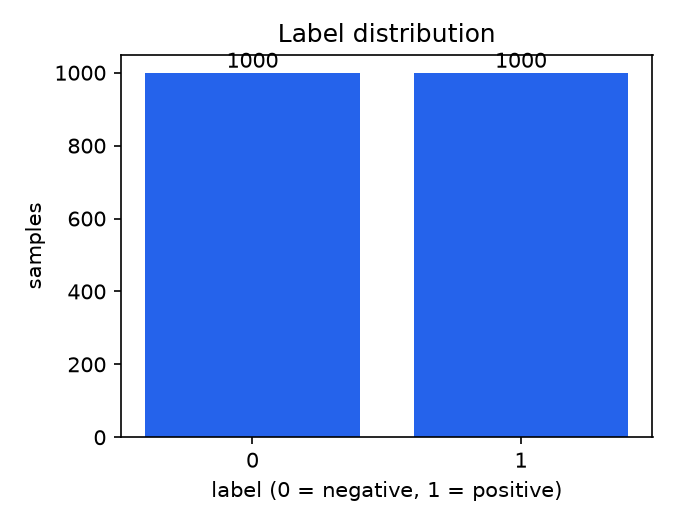

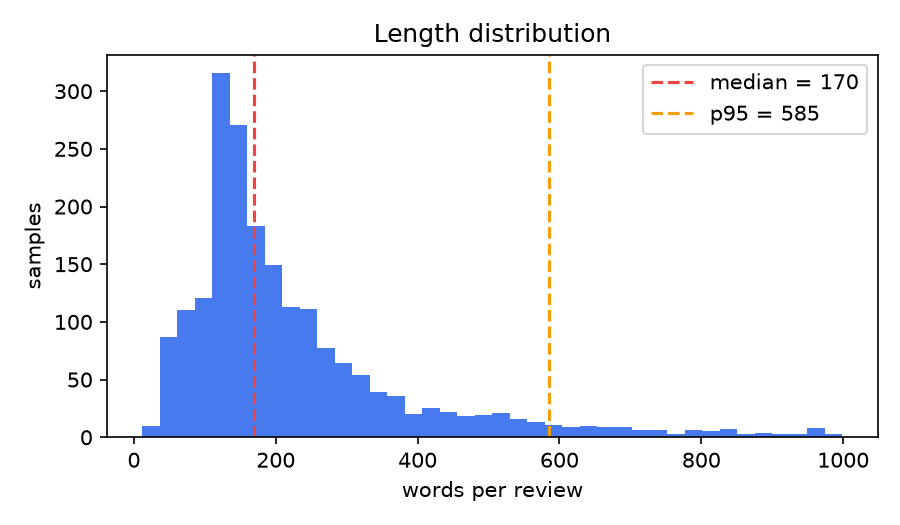

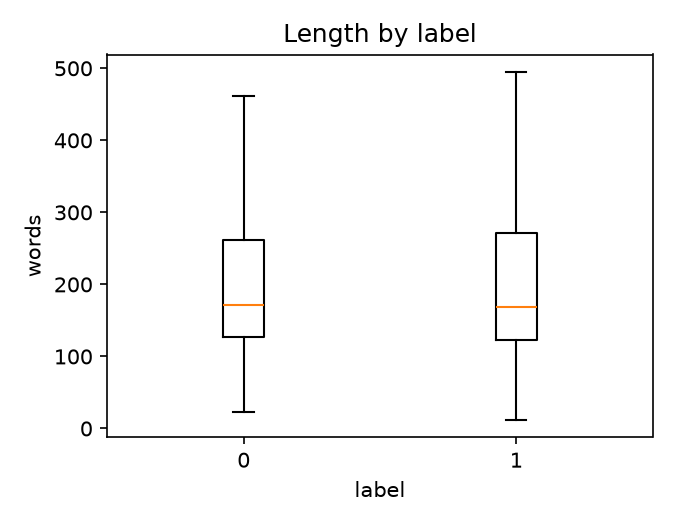

In [4]:
# Owner: Member A - hiển thị biểu đồ EDA
from pathlib import Path
from IPython.display import Image, display
fig_dir = Path(artifact_dir('lab3', 'figures'))
for f in ('label_distribution', 'length_distribution', 'length_by_label'):
    display(Image(str(fig_dir / f'{f}.png')))

In [5]:
# Owner: Member A - tokenize. Dùng tokenizer cùng checkpoint với model của B
# (không phụ thuộc cell 5.2 vì mục 5.2 chạy SAU mục 4)
from transformers import AutoTokenizer
tok_demo = AutoTokenizer.from_pretrained('distilbert-base-uncased')

tok_train = tokenize_dataset(train_ds, tok_demo, max_length=256)
print(tok_train.column_names)
ex = tok_train[0]
print({k: (v[:12] if isinstance(v, list) else v) for k, v in ex.items()})
n_hit = sum(len(x) >= 256 for x in tok_train['input_ids'])
print(f'Review đạt max_length=256 token (bị cắt hoặc vừa đủ): {n_hit}/{len(tok_train)} = {n_hit/len(tok_train):.1%}')

['label', 'input_ids', 'attention_mask']
{'label': 1, 'input_ids': [101, 2045, 2003, 2053, 7189, 2012, 2035, 2090, 3481, 3771, 1998, 6337], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
Review đạt max_length=256 token (bị cắt hoặc vừa đủ): 802/2000 = 40.1%


**Observations (from our real run, seed 42):**
- Labels: train 1000 / 1000; val 243 / 257 (0 / 1); test 254 / 246. Val and test are random samples, so they are close to balanced but not exactly.
- Review length in words (train, `run_eda`): mean 226, median 170, p95 585, min 12, max 999. The distribution is right-skewed (mean > median): a few very long reviews pull the mean up.
- Tokenized columns: `label`, `input_ids`, `attention_mask` (`text` is dropped; no padding yet, Member B pads per batch).
- Share of reviews that reach `max_length=256` tokens: 802 / 2000 = 40.1% (cut, or exactly 256 tokens). So `max_length=256` truncates a large part of the training reviews; its effect on accuracy is not measured here.

*Nhận xét (từ lần chạy thật, seed 42):* nhãn train cân bằng 1000/1000, val 243/257 và test 254/246 là mẫu ngẫu nhiên nên gần cân bằng chứ không tuyệt đối; độ dài (số từ) trung bình 226, trung vị 170, p95 585, lệch phải; dataset đã tokenize có `label`, `input_ids`, `attention_mask`; tỉ lệ review đạt 256 token: 802/2000 = 40,1%.

## 5. Models
### 5.1 Exercise 1: pre-trained sentiment pipeline (zero-shot)
**Owner: Member A.** Calls: `show_tokens`, `analyze_sentences` on 3 or more sample sentences. Note which default model the pipeline downloads.

---

**Tiếng Việt**

## 5. Mô hình
### 5.1 Bài 1: pipeline cảm xúc pre-trained (zero-shot)
**Phụ trách: Member A.** Gọi: `show_tokens`, `analyze_sentences` trên từ 3 câu mẫu. Ghi lại pipeline tải model mặc định nào.

In [6]:
# Owner: Member A
sentences = ['I love this movie', 'The plot was boring', 'Not bad at all']
for s in sentences:
    out = show_tokens(s)
    print(out['tokens']); print(out['input_ids']); print()
analyze_sentences(sentences)

['[CLS]', 'i', 'love', 'this', 'movie', '[SEP]']
[101, 1045, 2293, 2023, 3185, 102]

['[CLS]', 'the', 'plot', 'was', 'boring', '[SEP]']
[101, 1996, 5436, 2001, 11771, 102]

['[CLS]', 'not', 'bad', 'at', 'all', '[SEP]']
[101, 2025, 2919, 2012, 2035, 102]



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:  14%|█▍        | 15/104 [00:00<00:01, 56.52it/s]

Loading weights:  22%|██▏       | 23/104 [00:00<00:01, 57.57it/s]

Loading weights:  28%|██▊       | 29/104 [00:00<00:02, 26.37it/s]

...

Loading weights:  58%|█████▊    | 60/104 [00:02<00:02, 15.38it/s]

Loading weights:  81%|████████  | 84/104 [00:03<00:00, 32.22it/s]

Loading weights:  86%|████████▌ | 89/104 [00:03<00:00, 33.47it/s]

Loading weights: 100%|██████████| 104/104 [00:03<00:00, 33.21it/s]

[{'sentence': 'I love this movie',
  'label': 'POSITIVE',
  'score': 0.9998766183853149},
 {'sentence': 'The plot was boring',
  'label': 'NEGATIVE',
  'score': 0.9998039603233337},
 {'sentence': 'Not bad at all',
  'label': 'POSITIVE',
  'score': 0.9991185069084167}]

**Default model:** `analyze_sentences(model_name=None)` loads `distilbert-base-uncased-finetuned-sst-2-english` (a DistilBERT already fine-tuned on SST-2). `show_tokens(model_name=None)` uses the tokenizer of the same checkpoint.

**Observations (from our real run):** tokens are lowercase (uncased tokenizer) and every sentence starts with `[CLS]` (id 101) and ends with `[SEP]` (id 102). Predictions: "I love this movie" -> POSITIVE (0.9999); "The plot was boring" -> NEGATIVE (0.9998); "Not bad at all" -> POSITIVE (0.9991), which is the right reading of this negation. With only 3 sentences we cannot say how the model handles negation in general.

*Model mặc định:* `distilbert-base-uncased-finetuned-sst-2-english`. *Nhận xét (từ lần chạy thật):* token viết thường (tokenizer uncased), mỗi câu bắt đầu bằng `[CLS]` (id 101) và kết thúc bằng `[SEP]` (id 102). Kết quả: "I love this movie" -> POSITIVE (0.9999); "The plot was boring" -> NEGATIVE (0.9998); "Not bad at all" -> POSITIVE (0.9991), đúng với nghĩa của câu phủ định này. Chỉ có 3 câu nên chưa thể kết luận model xử lý phủ định tốt nói chung.

### 5.2 Exercise 2: model for fine-tuning
**Owner: Member B.** Call: `load_model_and_tokenizer('distilbert-base-uncased', num_labels=2)`. Tokenizer and model come from the same checkpoint.

---

**Tiếng Việt**

### 5.2 Bài 2: model để fine-tune
**Phụ trách: Member B.** Gọi: `load_model_and_tokenizer('distilbert-base-uncased', num_labels=2)`. Tokenizer và model cùng một checkpoint.

In [7]:
# Owner: Member B
# B's functions are imported here too (cell 3 lists only part of them), so this section is self-contained.
from labs.lab3.model.model import load_model_and_tokenizer
from labs.lab3.features.features import tokenize_dataset
from labs.lab3.train.train import build_training_args, train_with_trainer
from labs.lab3.evaluate.evaluate import (classification_metrics, compute_metrics, evaluate_on_test,
                                         predict_texts, zero_shot_labels)

MODEL_NAME = 'distilbert-base-uncased'
set_seed(SEED)
model, tokenizer = load_model_and_tokenizer(MODEL_NAME, num_labels=2)  # a warning about NEW (random) classifier weights is expected
assert model.name_or_path == tokenizer.name_or_path == MODEL_NAME      # model and tokenizer come from the same checkpoint
n_params = sum(p.numel() for p in model.parameters())
print('model     :', type(model).__name__, f'({n_params / 1e6:.1f}M parameters)')
print('checkpoint:', model.name_or_path, '| tokenizer:', tokenizer.name_or_path)
print('id2label  :', model.config.id2label)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights:  23%|██▎       | 23/100 [00:00<00:00, 181.51it/s]

Loading weights:  42%|████▏     | 42/100 [00:01<00:02, 28.15it/s] 

Loading weights:  51%|█████     | 51/100 [00:01<00:01, 33.34it/s]

Loading weights:  59%|█████▉    | 59/100 [00:02<00:01, 23.25it/s]

...

Loading weights:  81%|████████  | 81/100 [00:03<00:00, 23.27it/s]

Loading weights:  85%|████████▌ | 85/100 [00:03<00:00, 24.70it/s]

Loading weights: 100%|██████████| 100/100 [00:03<00:00, 30.65it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model     : DistilBertForSequenceClassification (67.0M parameters)
checkpoint: distilbert-base-uncased | tokenizer: distilbert-base-uncased
id2label  : {0: 'NEGATIVE', 1: 'POSITIVE'}


## 6. Training
### 6.1 Exercise 1
No training: the pipeline model is used as it is.

### 6.2 Exercise 2: fine-tuning with `Trainer`
**Owner: Member B.** The next cell tokenizes the three subsets, then calls `build_training_args` and `train_with_trainer` once and saves the model under `artifacts/models/` (not committed). If a saved model already exists it is loaded instead, so re-running the notebook does not train again (set `FORCE_TRAIN = True` to train again). Only train and validation are used for training and for choosing the best epoch; test is not touched here. The cell after it shows the loss curve and the metrics of each epoch. Argument names of `TrainingArguments` depend on the installed library version (handled inside `build_training_args`).

---

**Tiếng Việt**

## 6. Huấn luyện
### 6.1 Bài 1
Không huấn luyện: dùng model của pipeline nguyên trạng.

### 6.2 Bài 2: fine-tune bằng `Trainer`
**Phụ trách: Member B.** Cell dưới tokenize ba tập con, rồi gọi `build_training_args` và `train_with_trainer` một lần và lưu model vào `artifacts/models/` (không commit). Nếu đã có model lưu sẵn thì nạp lại, nên chạy lại notebook không huấn luyện lại (đặt `FORCE_TRAIN = True` để huấn luyện lại). Chỉ train và validation được dùng để huấn luyện và chọn epoch tốt nhất; ở đây không đụng tới test. Cell kế tiếp hiển thị đường loss và metric từng epoch. Tên tham số `TrainingArguments` phụ thuộc phiên bản thư viện đã cài (được xử lý trong `build_training_args`).

In [8]:
# Owner: Member B
import json
from pathlib import Path

# ---- settings. On a slow CPU use MAX_LEN = 128 and/or EPOCHS = 1 for a shorter run. ----
MAX_LEN, EPOCHS, LR, BATCH = 128, 1, 2e-5, 8
FORCE_TRAIN = False  # False: reuse the saved model if it exists. True: train again.
MODEL_DIR = Path(artifact_dir('lab3', 'models')) / 'distilbert_imdb'          # not committed (.gitignore)
LOG_FILE = Path(artifact_dir('lab3', 'logs')) / 'distilbert_imdb_log.json'    # not committed (.gitignore)

# Tokenize with the tokenizer of the model. Truncation only: the Trainer pads per batch (DataCollatorWithPadding).
tok_train = tokenize_dataset(train_ds, tokenizer, max_length=MAX_LEN)
tok_val = tokenize_dataset(val_ds, tokenizer, max_length=MAX_LEN)
tok_test = tokenize_dataset(test_ds, tokenizer, max_length=MAX_LEN)
print('columns:', tok_train.column_names, '| sizes (train/val/test):', len(tok_train), len(tok_val), len(tok_test))

args = build_training_args(MODEL_DIR, epochs=EPOCHS, lr=LR, batch_size=BATCH, seed=SEED)
if FORCE_TRAIN or not (MODEL_DIR / 'config.json').exists():
    set_seed(SEED)
    model, tokenizer = load_model_and_tokenizer(MODEL_NAME, num_labels=2)  # fresh pre-trained weights (never train a trained model again)
    trainer = train_with_trainer(model, tok_train, tok_val, args, compute_metrics, tokenizer=tokenizer)
    log_history = trainer.state.log_history
    LOG_FILE.write_text(json.dumps(log_history, indent=1), encoding='utf-8')
    print('fine-tuned and saved to', MODEL_DIR)
else:
    import inspect
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, Trainer
    tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR))
    model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_DIR))
    tok_key = 'processing_class' if 'processing_class' in inspect.signature(Trainer.__init__).parameters else 'tokenizer'
    trainer = Trainer(model=model, args=args, eval_dataset=tok_val, data_collator=DataCollatorWithPadding(tokenizer),
                      compute_metrics=compute_metrics, **{tok_key: tokenizer})  # evaluation only
    log_history = json.loads(LOG_FILE.read_text(encoding='utf-8')) if LOG_FILE.exists() else []
    print('loaded the saved model from', MODEL_DIR, '(no training)')

columns: ['label', 'input_ids', 'attention_mask'] | sizes (train/val/test): 2000 500 500


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   8%|▊         | 8/104 [00:00<00:06, 15.22it/s]

Loading weights:  12%|█▏        | 12/104 [00:00<00:04, 19.83it/s]

Loading weights:  14%|█▍        | 15/104 [00:00<00:04, 19.35it/s]

...

Loading weights:  78%|███████▊  | 81/104 [00:03<00:00, 32.38it/s]

Loading weights:  85%|████████▍ | 88/104 [00:03<00:00, 32.04it/s]

Loading weights:  90%|█████████ | 94/104 [00:03<00:00, 35.05it/s]

Loading weights: 100%|██████████| 104/104 [00:03<00:00, 31.06it/s]

loaded the saved model from /workspaces/Lab-DL/labs/lab3/artifacts/models/distilbert_imdb (no training)


In [9]:
# Owner: Member B - training log: loss per logged step and the metrics at the end of each epoch
import matplotlib.pyplot as plt
import pandas as pd

if not log_history:
    print('No training log found. Set FORCE_TRAIN = True in the previous cell to train and write the log.')
else:
    steps = [r['step'] for r in log_history if 'loss' in r]
    losses = [r['loss'] for r in log_history if 'loss' in r]
    if losses:
        plt.figure(figsize=(6, 3.2))
        plt.plot(steps, losses, marker='o', ms=3)
        plt.xlabel('step'); plt.ylabel('training loss'); plt.title('Fine-tuning: training loss'); plt.grid(alpha=0.3)
        plt.show()
        print(f'training loss: first logged {losses[0]:.4f} -> last logged {losses[-1]:.4f} ({len(losses)} logged points)')
    epoch_rows = [r for r in log_history if 'eval_f1' in r]
    if epoch_rows:
        print(pd.DataFrame(epoch_rows)[['epoch', 'eval_loss', 'eval_accuracy', 'eval_f1']].round(4).to_string(index=False))

training loss: first logged 0.6912 -> last logged 0.4108 (25 logged points)
 epoch  eval_loss  eval_accuracy  eval_f1
   1.0     0.3607          0.834   0.8337


## 7. Evaluation on validation
**Owner: Member B.** Accuracy and F1 from `compute_metrics` on the validation subset. Choices (epochs, lr, max_length) are made here, never on test.

---

**Tiếng Việt**

## 7. Đánh giá trên validation
**Phụ trách: Member B.** Accuracy và F1 từ `compute_metrics` trên tập validation con. Mọi lựa chọn (epoch, lr, max_length) làm ở đây, không bao giờ trên test.

In [10]:
# Owner: Member B - validation metrics of the final model (the epoch with the best validation f1 is kept)
from math import sqrt

val_metrics = trainer.evaluate(eval_dataset=tok_val)  # keys are prefixed with 'eval_'
acc, f1 = val_metrics['eval_accuracy'], val_metrics['eval_f1']
se = sqrt(acc * (1 - acc) / len(tok_val))
print(f"validation (n = {len(tok_val)}): accuracy = {acc:.4f}, f1 = {f1:.4f}, loss = {val_metrics['eval_loss']:.4f}")
print(f'standard error of the accuracy: about {se * 100:.1f} points')
print('Note: the best epoch was picked on this same validation set, so this number is slightly optimistic; the unbiased number is the test result in section 10.')

/workspaces/Lab-DL/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.360743,0,0.834000,0.833667


validation (n = 500): accuracy = 0.8340, f1 = 0.8337, loss = 0.3607
standard error of the accuracy: about 1.7 points
Note: the best epoch was picked on this same validation set, so this number is slightly optimistic; the unbiased number is the test result in section 10.


## 8. Predictions and errors
**Owner: Member B.** Call: `predict_texts(model, tokenizer, texts)`. Show a few wrong predictions with their text. Reasons for errors are hypotheses unless tested.

---

**Tiếng Việt**

## 8. Dự đoán và lỗi
**Phụ trách: Member B.** Gọi: `predict_texts(model, tokenizer, texts)`. Hiển thị vài câu đoán sai kèm văn bản. Lý do gây lỗi chỉ là giả thuyết nếu chưa kiểm chứng.

In [11]:
# Owner: Member B - predictions and errors on VALIDATION (the test set is not touched before section 10)
for r in predict_texts(model, tokenizer, ['I love this movie', 'The plot was boring', 'Not bad at all'], max_length=MAX_LEN):
    print(f"label = {r['label']} ({'POSITIVE' if r['label'] == 1 else 'NEGATIVE'}), score = {r['score']:.4f} | {r['text']}")

val_texts, val_labels = list(val_ds['text']), list(val_ds['label'])
preds = predict_texts(model, tokenizer, val_texts, max_length=MAX_LEN)
pred_labels = [p['label'] for p in preds]
m = classification_metrics(val_labels, pred_labels)
print(f"\npredict_texts on validation: accuracy = {m['accuracy']:.4f}, f1 = {m['f1']:.4f} (should be the same as section 7, up to tiny padding effects)")

tp = sum(y == 1 and p == 1 for y, p in zip(val_labels, pred_labels))
tn = sum(y == 0 and p == 0 for y, p in zip(val_labels, pred_labels))
fp = sum(y == 0 and p == 1 for y, p in zip(val_labels, pred_labels))
fn = sum(y == 1 and p == 0 for y, p in zip(val_labels, pred_labels))
print('\nconfusion matrix (rows = true label, columns = predicted label):')
print('         pred 0  pred 1')
print(f'true 0  {tn:6d}  {fp:6d}')
print(f'true 1  {fn:6d}  {tp:6d}')

wrong = sorted(((p['score'], y, p['label'], t) for t, y, p in zip(val_texts, val_labels, preds) if y != p['label']), reverse=True)
print(f'\n{len(wrong)} wrong out of {len(val_texts)}. The 5 most confident mistakes (reasons are hypotheses, not tested):')
for score, y, p, t in wrong[:5]:
    print(f"- true = {y}, predicted = {p}, score = {score:.3f}: {t[:300]}{'...' if len(t) > 300 else ''}")

label = 1 (POSITIVE), score = 0.9000 | I love this movie
label = 0 (NEGATIVE), score = 0.8555 | The plot was boring
label = 0 (NEGATIVE), score = 0.6667 | Not bad at all



predict_texts on validation: accuracy = 0.8340, f1 = 0.8337 (should be the same as section 7, up to tiny padding effects)

confusion matrix (rows = true label, columns = predicted label):
         pred 0  pred 1
true 0     209      34
true 1      49     208

83 wrong out of 500. The 5 most confident mistakes (reasons are hypotheses, not tested):
- true = 0, predicted = 1, score = 0.921: This is the version that even the author hated, because it's so schmaltzy. They gave it a 'happy ending' and changed a lot of the dialogue, and it's just a big pile of saccharine. The 'stage manager' is quite good, I believe he originated the role, but everyone else falls into that acting style of t...
- true = 0, predicted = 1, score = 0.914: this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the show at all 

## 9. Experiments (optional)
**Owner: Member B.** E.g. effect of `max_length` (128 vs 256) on validation.

**Noise:** with n = 500 samples, the standard error of accuracy is about sqrt(p(1-p)/n), about 1.3 points for p = 0.9. With one seed per setting, differences smaller than about 2 standard errors are not evidence that one setting is better.

---

**Tiếng Việt**

## 9. Thí nghiệm (tùy chọn)
**Phụ trách: Member B.** Vd ảnh hưởng của `max_length` (128 và 256) trên validation.

**Sai số:** với n = 500 mẫu, sai số chuẩn của accuracy khoảng sqrt(p(1-p)/n), khoảng 1,3 điểm % khi p = 0,9. Mỗi cấu hình chỉ chạy một seed thì chênh lệch nhỏ hơn khoảng 2 lần sai số chuẩn chưa chứng minh được cấu hình nào tốt hơn.

In [12]:
# Owner: Member B (optional) - effect of max_length on validation. OFF by default: it trains a second model.
RUN_EXPERIMENT = False
ALT_LEN = 128

if not RUN_EXPERIMENT:
    print(f'skipped. Set RUN_EXPERIMENT = True to compare max_length = {ALT_LEN} with max_length = {MAX_LEN} on validation.')
else:
    set_seed(SEED)
    alt_model, alt_tok = load_model_and_tokenizer(MODEL_NAME, num_labels=2)
    alt_train = tokenize_dataset(train_ds, alt_tok, max_length=ALT_LEN)
    alt_val = tokenize_dataset(val_ds, alt_tok, max_length=ALT_LEN)
    alt_args = build_training_args(MODEL_DIR.parent / f'distilbert_imdb_len{ALT_LEN}', epochs=EPOCHS, lr=LR, batch_size=BATCH, seed=SEED)
    alt_trainer = train_with_trainer(alt_model, alt_train, alt_val, alt_args, compute_metrics, tokenizer=alt_tok)
    alt = alt_trainer.evaluate(eval_dataset=alt_val)
    diff = (alt['eval_accuracy'] - acc) * 100
    print(f"validation accuracy: max_length {ALT_LEN} = {alt['eval_accuracy']:.4f} | max_length {MAX_LEN} = {acc:.4f} | difference = {diff:+.1f} points")
    print('within sampling noise (one seed, difference < 2 standard errors): no evidence either setting is better.'
          if abs(diff) < 2 * se * 100 else
          'larger than 2 standard errors, but still one seed on one subset: treat it as a hint, not a proof.')

skipped. Set RUN_EXPERIMENT = True to compare max_length = 128 with max_length = 128 on validation.


## 10. Final test (not used to choose the model)
### 10.1 Fine-tuned model
**Owner: Member B.** Call: `evaluate_on_test(trainer, tok_test)`.

### 10.2 Zero-shot vs fine-tuned on the same test subset
**Owner: Member B.** Zero-shot labels come from A's `analyze_sentences` (mapped POSITIVE -> 1, NEGATIVE -> 0); fine-tuned results from `evaluate_on_test`. Table: model, accuracy, F1, same 500 test texts, with a note on sampling error.

---

**Tiếng Việt**

## 10. Test cuối (không dùng để chọn model)
### 10.1 Model đã fine-tune
**Phụ trách: Member B.** Gọi: `evaluate_on_test(trainer, tok_test)`.

### 10.2 So sánh zero-shot và fine-tune trên cùng tập test
**Phụ trách: Member B.** Nhãn zero-shot lấy từ hàm `analyze_sentences` của A (đổi POSITIVE -> 1, NEGATIVE -> 0); kết quả fine-tune từ `evaluate_on_test`. Bảng: model, accuracy, F1, cùng 500 văn bản test, kèm lưu ý về sai số.

In [13]:
# Owner: Member B - 10.1 FINAL test evaluation of the fine-tuned model. Run once: never use it to choose epochs, lr or max_length.
test_metrics = evaluate_on_test(trainer, tok_test)
print({k: round(v, 4) for k, v in test_metrics.items() if k in ('loss', 'accuracy', 'f1')})

Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.380344,0,0.822000,0.819473


{'loss': 0.3803, 'accuracy': 0.822, 'f1': 0.8195}


In [14]:
# Owner: Member B - 10.2 zero-shot (Exercise 1) vs fine-tuned (Exercise 2) on the SAME test reviews
import json
from math import sqrt
from pathlib import Path
import pandas as pd

test_texts, y_test = list(test_ds['text']), list(test_ds['label'])
n = len(y_test)
assert n == len(tok_test)  # both models are scored on the same reviews

zs_results = analyze_sentences(test_texts)  # Member A's function: SST-2 pipeline, no extra training
zs = classification_metrics(y_test, zero_shot_labels(zs_results))  # POSITIVE -> 1, NEGATIVE -> 0
ft = {'accuracy': test_metrics['accuracy'], 'f1': test_metrics['f1']}

table = pd.DataFrame({'zero-shot (Exercise 1)': zs, 'fine-tuned (Exercise 2)': ft}).T[['accuracy', 'f1']]
display(table.round(4))

se_pts = {name: sqrt(a * (1 - a) / n) * 100 for name, a in table['accuracy'].items()}
diff = (ft['accuracy'] - zs['accuracy']) * 100
diff_f1 = (ft['f1'] - zs['f1']) * 100
print(f'n = {n} test reviews. Standard error of the accuracy: ' + ', '.join(f'{k} {v:.1f} points' for k, v in se_pts.items()))
if abs(diff) < 2.5:
    verdict = 'within sampling noise: no evidence that one model is better'
elif abs(diff) < 3.0:
    verdict = 'borderline (2.5 to 3 points): not clear evidence'
else:
    verdict = f"larger than the noise: {'fine-tuned' if diff > 0 else 'zero-shot'} is better on this subset (one seed, one subset)"
print(f'accuracy difference (fine-tuned - zero-shot) = {diff:+.1f} points -> {verdict}')
print(f'F1 difference (fine-tuned - zero-shot) = {diff_f1:+.1f} points')
print(f'Note: the zero-shot pipeline truncates reviews at 512 tokens, the fine-tuned model at {MAX_LEN} tokens.')

results = {'n_test': n, 'max_len': MAX_LEN, 'epochs': EPOCHS, 'seed': SEED, 'zero_shot': zs, 'fine_tuned': ft}
Path(artifact_dir('lab3', 'logs'), 'lab3_results.json').write_text(json.dumps(results, indent=1), encoding='utf-8')
print(f"\nFor progress_status.md: test n={n}, zero-shot acc/F1 = {zs['accuracy']:.4f}/{zs['f1']:.4f}, "
      f"fine-tuned acc/F1 = {ft['accuracy']:.4f}/{ft['f1']:.4f} (MAX_LEN={MAX_LEN}, EPOCHS={EPOCHS}, seed={SEED})")

,accuracy,f1
zero-shot (Exercise 1),0.892,0.8889
fine-tuned (Exercise 2),0.822,0.8195


n = 500 test reviews. Standard error of the accuracy: zero-shot (Exercise 1) 1.4 points, fine-tuned (Exercise 2) 1.7 points
accuracy difference (fine-tuned - zero-shot) = -7.0 points -> larger than the noise: zero-shot is better on this subset (one seed, one subset)
F1 difference (fine-tuned - zero-shot) = -6.9 points
Note: the zero-shot pipeline truncates reviews at 512 tokens, the fine-tuned model at 128 tokens.

For progress_status.md: test n=500, zero-shot acc/F1 = 0.8920/0.8889, fine-tuned acc/F1 = 0.8220/0.8195 (MAX_LEN=128, EPOCHS=1, seed=42)


## 11. Summary
**Owner: team leader.** 3-5 modest sentences based only on the outputs above (to be written after the runs).

---

**Tiếng Việt**

## 11. Tổng kết
**Phụ trách: nhóm trưởng.** 3-5 câu khiêm tốn, chỉ dựa trên output phía trên (viết sau khi chạy).

## 12. Appendix
**Owner: team leader.** Extra work only if understood (inspect wrong predictions, effect of max_length). Out of scope: LoRA, cleanlab, ensemble. Dataset citation: Maas et al., ACL 2011.

---

**Tiếng Việt**

## 12. Phụ lục
**Phụ trách: nhóm trưởng.** Phần làm thêm chỉ khi hiểu (xem câu đoán sai, ảnh hưởng của max_length). Ngoài phạm vi: LoRA, cleanlab, ensemble. Trích dẫn dữ liệu: Maas et al., ACL 2011.